# MAGIC imputation (ArchR `addImputeWeights` / `imputeMatrix`)

scATAC gene scores are extremely sparse: most cells have zero signal for any
single gene, so a raw gene-score UMAP looks like salt-and-pepper noise. ArchR
smooths these values with **MAGIC** (van Dijk et al., *Cell* 2018): every cell
is replaced by a weighted average of its neighbours in the reduced-dimension
space.

`epi.tl.add_impute_weights` and `epi.tl.impute_matrix` are line-by-line ports
of ArchR's `addImputeWeights` and `imputeMatrix` (ArchR 1.0.3,
`R/Imputation.R`). Their agreement with ArchR is summarised at the end of this
notebook.

```{note}
`scanpy.external.pp.magic` only calls the separate `magic-impute` package; scanpy
itself contains no MAGIC algorithm. The specification ported here is ArchR's own
adaptation, which differs from `magic-impute` (random cell blocks, self-loops,
`W^(td+1)` diffusion, averaging over replicates), so Epione does not depend on
either package.
```

## What ArchR computes

For each of `n_rep` replicates the cells are shuffled and cut into blocks of
about `sample_cells` cells. Inside each block:

1. find the `k` nearest neighbours of every cell (the cell itself counts as
   neighbour 1) on the reduced dimensions;
2. **autotune**: divide each cell's distances by the distance to its `ka`-th
   neighbour, so dense and sparse regions get a comparable kernel width;
3. build the symmetric kernel $W = \exp\!\big(-(D + D^\top)/\epsilon^2\big)$ on
   the kNN pattern. The zero self-distance is kept, so every cell carries a
   self-loop of weight 1;
4. Markov-normalise the rows and diffuse: $W_t = W^{\,td+1}$.

`impute_matrix` multiplies each block operator into its cells' values and
averages the replicates.

## Data

This tutorial uses the ArchR hematopoiesis data (BMMC, CD34+ BMMC and PBMC,
hg19) preprocessed entirely with Epione. The dataset tutorial
[`t_archr_heme_data`](t_archr_heme_data.ipynb) downloads the fragments and
builds every file used here. Set `EPIONE_ARCHR_HEME` to the directory it
wrote; the default is `data_archr_heme/` next to this notebook.

We need `heme_gene_scores.h5ad`: Epione's ArchR-model gene scores
(`epi.tl.add_gene_score_matrix`), the `X_iterative_lsi` embedding, the UMAP
and the Leiden clusters.

In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import anndata as ad
import matplotlib as mpl
import matplotlib.pyplot as plt
import epione as epi

DATA = Path(os.environ.get('EPIONE_ARCHR_HEME', 'data_archr_heme'))

In [2]:
%%time
adata = ad.read_h5ad(DATA / 'heme_gene_scores.h5ad')
adata

CPU times: user 48.2 ms, sys: 115 ms, total: 163 ms
Wall time: 164 ms


AnnData object with n_obs × n_vars = 10705 × 20057
    obs: 'Sample', 'n_fragment', 'tsse', 'Clusters'
    var: 'chrom', 'start', 'end', 'strand'
    uns: 'files'
    obsm: 'X_iterative_lsi', 'X_umap'

ArchR's `getReducedDims()` hands `addImputeWeights` the LSI with each cell
z-scored across dimensions (`scaleDims = TRUE`, the `IterativeLSI` default) and
the depth-correlated dimensions removed. Epione's `iterative_lsi` already drops
the depth-correlated dimension, so we only ask for the row scaling with
`scale_dims=True`.

## Compute impute weights

In [3]:
%%time
epi.tl.add_impute_weights(
    adata,
    use_rep='X_iterative_lsi',
    scale_dims=True,     # ArchR getReducedDims(scaleDims = TRUE)
    sample_cells=5000,   # ArchR defaults
    n_rep=2,
    k=15, td=3, ka=4, epsilon=1,
    seed=1,              # rng='R' (default): the blocks ArchR draws with set.seed(1), threads = 1
)
iw = adata.uns['impute_weights']
[(len(rep), [len(b['cells']) for b in rep]) for rep in iw['weights']]

  └─ [add_impute_weights] replicate 1/2: 2 block(s) of ~5,353 cells


  └─ [add_impute_weights] replicate 2/2: 2 block(s) of ~5,353 cells


CPU times: user 10.7 s, sys: 827 ms, total: 11.5 s
Wall time: 11.5 s


[(2, [5353, 5352]), (2, [5353, 5352])]

Every block operator is row-stochastic, and every cell keeps some of its own
signal through the self-loop:

In [4]:
W = iw['weights'][0][0]['weights']
print('shape', W.shape, '| row sums', W.sum(1).min().round(12), W.sum(1).max().round(12))
print('fraction non-zero', round((W > 0).mean(), 3), '| median self weight', round(np.median(np.diag(W)), 4))

shape (5353, 5353) | row sums 1.0 1.0
fraction non-zero 0.889 | median self weight 0.0208


## Impute marker gene scores

In [5]:
%%time
markers = ['CD34', 'GATA1', 'PAX5', 'MS4A1', 'CD14', 'CD3D']
imputed = epi.tl.impute_matrix(adata, genes=markers)
raw = adata[:, markers].X.toarray()
imputed.shape

CPU times: user 451 ms, sys: 21.9 ms, total: 473 ms
Wall time: 183 ms


(10705, 6)

### Raw vs imputed gene scores on the UMAP

Same styling as ArchR `plotEmbedding(colorBy = "GeneScoreMatrix")`:
`log2(x + 1)`, values clipped to the 1–99 % quantiles, `horizonExtra` palette.

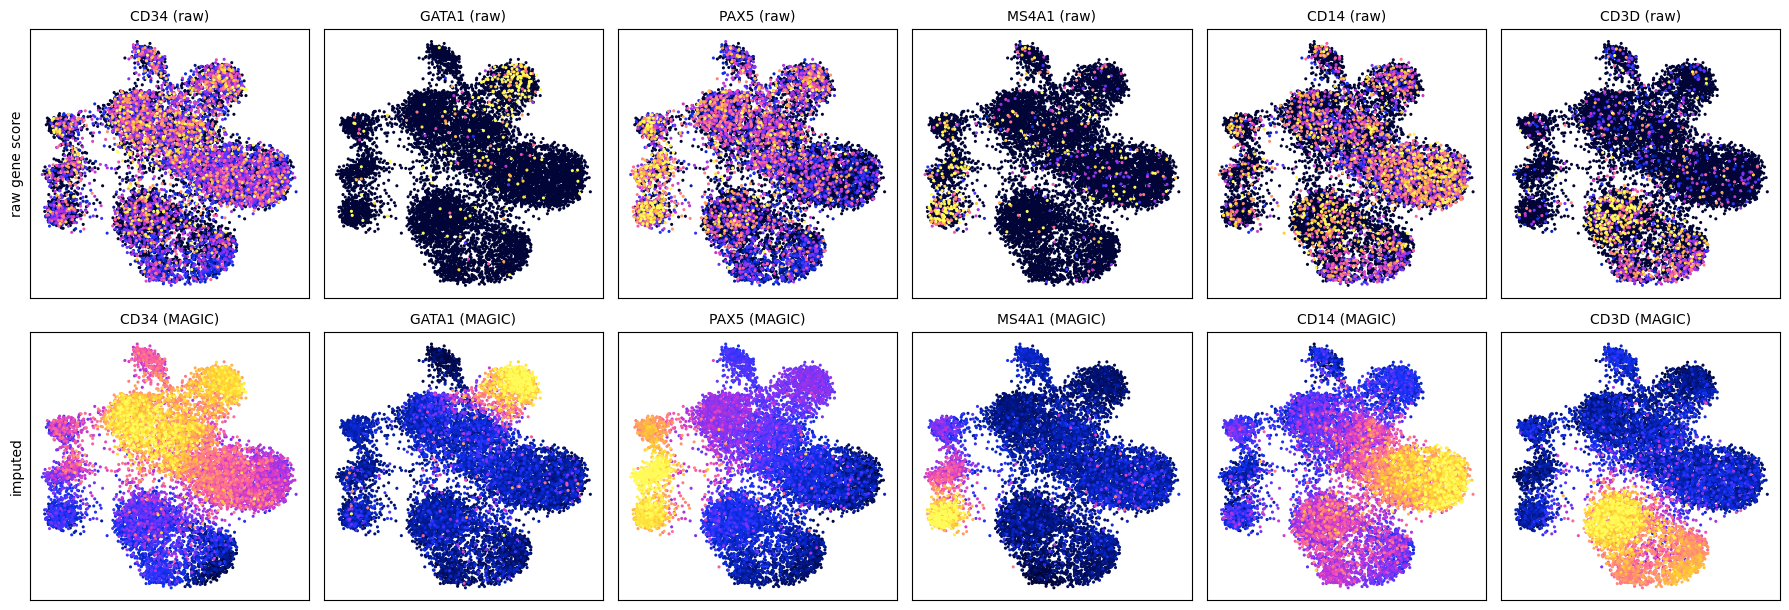

In [6]:
HORIZON = mpl.colors.LinearSegmentedColormap.from_list('horizonExtra', [
    '#000436', '#021EA9', '#1632FB', '#6E34FC', '#C732D5',
    '#FD619D', '#FF9965', '#FFD32B', '#FFFC5A'])

def qcut(x, lo=0.01, hi=0.99):
    q = np.quantile(x, [lo, hi])
    if q[1] == 0:
        q[1] = x.max()
    return np.clip(x, q[0], q[1])

umap = adata.obsm['X_umap']
fig, axes = plt.subplots(2, len(markers), figsize=(3 * len(markers), 6.2))
for j, g in enumerate(markers):
    for i, (lab, M) in enumerate([('raw', raw), ('MAGIC', imputed)]):
        v = qcut(np.log2(M[:, j] + 1))
        o = np.argsort(v)
        ax = axes[i, j]
        ax.scatter(umap[o, 0], umap[o, 1], c=v[o], cmap=HORIZON, s=1.5, rasterized=True)
        ax.set_title(f'{g} ({lab})', fontsize=10); ax.set_xticks([]); ax.set_yticks([])
axes[0, 0].set_ylabel('raw gene score'); axes[1, 0].set_ylabel('imputed')
plt.tight_layout(); plt.show()

### Which cluster lights up?

The clusters come from Epione's Leiden run, so their IDs differ from ArchR's.
Instead of hard-coding cluster names, we let the imputed scores pick them: for
each marker, the cluster with the highest mean imputed score. Smoothing also
lifts the background, so the top-to-median ratio is *smaller* after imputation:
what MAGIC adds is a per-cell signal without dropouts (the UMAPs above), not a
larger cluster-level contrast.

In [7]:
cl = adata.obs['Clusters'].astype(str)
def cluster_means(M):
    return pd.DataFrame(np.log2(M + 1), index=adata.obs_names, columns=markers).groupby(cl.to_numpy()).mean()

m_raw, m_imp = cluster_means(raw), cluster_means(imputed)
top = m_imp.idxmax()
pd.DataFrame({
    'top cluster': top,
    'raw: top / median of clusters': [m_raw.loc[top[g], g] / m_raw[g].median() for g in markers],
    'MAGIC: top / median of clusters': [m_imp.loc[top[g], g] / m_imp[g].median() for g in markers],
}).round(2)

,top cluster,raw: top / median of clusters,MAGIC: top / median of clusters
CD34,C4,1.43,1.19
GATA1,C5,14.52,5.52
PAX5,C9,2.02,1.80
MS4A1,C8,10.95,6.03
CD14,C1,2.11,1.35
CD3D,C2,5.77,3.22


### Plotting through `epi.pl.embedding`

`impute_matrix(..., layer_added=...)` stores the imputed values as a layer
(when every feature is imputed), which is the analogue of ArchR's
`plotEmbedding(imputeWeights = getImputeWeights(proj))`. Imputing all ~20k genes
is a ~2 GB dense matrix, so here we do it on a marker-only AnnData that carries
the same weights.

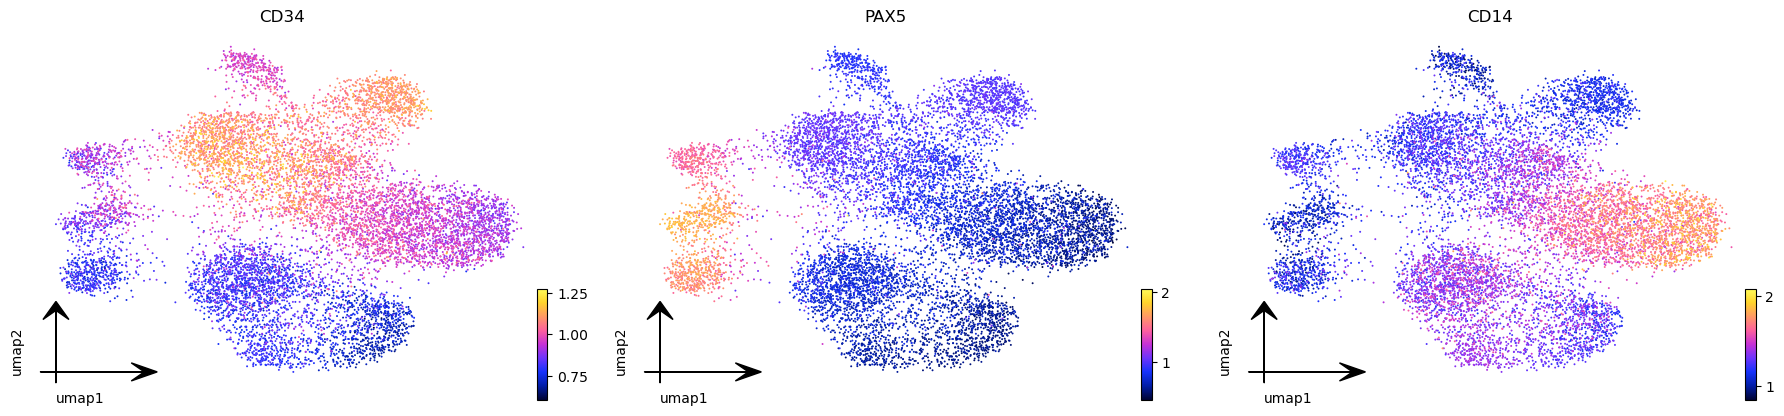

In [8]:
sub = adata[:, markers].copy()
_ = epi.tl.impute_matrix(sub, layer_added='magic')
sub.layers['magic'] = np.log2(sub.layers['magic'] + 1)   # ArchR log2-normalises after imputing
epi.pl.embedding(sub, basis='X_umap', color=['CD34', 'PAX5', 'CD14'], layer='magic',
                 cmap=HORIZON, frameon=False, ncols=3, size=8)

## Parity vs ArchR

The port was checked against ArchR 1.0.3 `addImputeWeights` + `imputeMatrix`
on ArchR's own hematopoiesis project (10,660 cells, ArchR's IterativeLSI and
GeneScoreMatrix; `sampleCells = 5000, nRep = 2, k = 15, td = 3, ka = 4,
epsilon = 1, seed = 1, threads = 1`). ArchR's reduced dimensions were fed to
Epione, and ArchR's sampled blocks, every block's diffusion matrix and the
imputed scores of a 99-gene panel were compared. The gates were registered
before the first comparison (`tests/parity/impute_magic/MANIFEST.md`). The
ArchR reference outputs are generated outside this repository;
`tests/test_impute_magic.py` re-runs the comparison when
`EPIONE_ARCHR_PARITY_DIR` points at them.

| # | Output | Mode | Value | Gate |
|---|---|---|---|---|
| 1 | Reduced dims fed to MAGIC | deterministic | max \|Δ\| 0 | ≤ 1e-6 ✅ |
| 2 | Block membership | ArchR's blocks injected (`blocks=`) | identical (2 reps × 2 blocks) | identical ✅ |
| 3 | Diffusion weights $W^{td+1}$ | ArchR's blocks injected | max \|Δ\| 5.6e-17 | ≤ 1e-6 ✅ |
| 4 | Imputed gene panel | ArchR's blocks injected | max \|Δ\| 1.1e-14 (relative 2.2e-15) | ≤ 1e-6 ✅ |
| 5 | Blocks / weights / imputed panel | free-running `rng="R"`, `seed=1` | identical / 5.6e-17 / 1.1e-14 | same as 2–4 ✅ |
| 6 | Imputed panel | free-running `rng="numpy"` | median gene Pearson 0.917 (min 0.483) | ≥ 0.95 ❌ |
| | *ArchR seed 1 vs ArchR seed 2* | *baseline* | *median gene Pearson 0.913 (min 0.539)* | |

Everything that depends only on the algorithm agrees to ~1e-14, and with
`rng="R"` Epione draws the same blocks as ArchR from the same seed. Row 6 fails
its pre-registered threshold, but ArchR against itself with a different seed
reaches only 0.913: ArchR builds each kNN graph inside a random half of the
cells, so two independent blockings legitimately disagree. The threshold was
set too high and is reported as failed rather than loosened.

## Notes

* `rng="R"` reproduces ArchR only for `threads = 1`: with more threads ArchR draws
  each replicate's permutation inside a forked worker that does not continue the
  `set.seed()` stream. Pass ArchR's blocks through `blocks=` to match such runs.
* The weights are dense float64 blocks (`sample_cells²` × 8 bytes each, ~230 MB
  per block for the defaults), like ArchR's HDF5 weight files.
* Use `scale_dims=True` / `depth_key=` when the embedding is not already
  row-scaled and depth-filtered (e.g. a raw SVD); Epione's `iterative_lsi`
  output already has its depth-correlated components removed.